In [ ]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns0

In [2]:
df=pd.read_csv('uber_trips_dataset_50k.csv')

In [3]:
df.head(5)

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time
0,1,8270,10683,San Francisco,37.170931,-77.586479,37.173652,-77.619934,2.97,10.71,Completed,Wallet,2023-01-01 00:00:00,2023-01-01 00:08:54.600000000
1,2,1860,44743,Boston,38.898127,-108.582977,38.937464,-108.558727,8.43,22.41,Completed,UPI,2023-01-01 00:01:00,2023-01-01 00:26:17.400000000
2,3,6390,75839,San Francisco,38.814571,-89.942603,38.821702,-89.896435,5.46,12.91,Completed,Cash,2023-01-01 00:02:00,2023-01-01 00:18:22.800000000
3,4,6191,22189,New York,37.295906,-75.328844,37.301375,-75.317488,6.61,15.70,Completed,Wallet,2023-01-01 00:03:00,2023-01-01 00:22:49.800000000
4,5,6734,61104,Seattle,38.972395,-121.482913,38.992088,-121.467904,10.50,19.15,Completed,Wallet,2023-01-01 00:04:00,2023-01-01 00:35:30.000000000


In [4]:
df.tail()

,trip_id,driver_id,rider_id,city,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount,status,payment_method,pickup_time,drop_time
49995,49996,4836,99552,Boston,39.087594,-92.313909,39.124554,-92.361690,7.39,18.37,No-Show,Card,2023-02-04 17:15:00,2023-02-04 17:37:10.200000000
49996,49997,8309,35750,Los Angeles,39.629770,-83.081404,39.580352,-83.050452,4.89,14.39,Completed,Cash,2023-02-04 17:16:00,2023-02-04 17:30:40.200000000
49997,49998,8381,36652,San Francisco,37.052628,-89.241586,37.094407,-89.193332,4.19,13.22,Completed,Card,2023-02-04 17:17:00,2023-02-04 17:29:34.199999999
49998,49999,5474,43848,Chicago,37.588881,-117.889704,37.612300,-117.886773,2.31,6.72,Cancelled,Card,2023-02-04 17:18:00,2023-02-04 17:24:55.800000000
49999,50000,9683,34776,San Francisco,40.292170,-112.706632,40.325930,-112.723538,9.97,23.47,Cancelled,Wallet,2023-02-04 17:19:00,2023-02-04 17:48:54.600000000


In [5]:
df.shape

(50000, 14)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 14 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   trip_id         50000 non-null  int64  
 1   driver_id       50000 non-null  int64  
 2   rider_id        50000 non-null  int64  
 3   city            50000 non-null  object 
 4   pickup_lat      50000 non-null  float64
 5   pickup_lng      50000 non-null  float64
 6   drop_lat        50000 non-null  float64
 7   drop_lng        50000 non-null  float64
 8   distance_km     50000 non-null  float64
 9   fare_amount     50000 non-null  float64
 10  status          50000 non-null  object 
 11  payment_method  50000 non-null  object 
 12  pickup_time     50000 non-null  object 
 13  drop_time       50000 non-null  object 
dtypes: float64(6), int64(3), object(5)
memory usage: 5.3+ MB


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df.isnull().sum()

trip_id           0
driver_id         0
rider_id          0
city              0
pickup_lat        0
pickup_lng        0
drop_lat          0
drop_lng          0
distance_km       0
fare_amount       0
status            0
payment_method    0
pickup_time       0
drop_time         0
dtype: int64

In [9]:
df.describe()

,trip_id,driver_id,rider_id,pickup_lat,pickup_lng,drop_lat,drop_lng,distance_km,fare_amount
count,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,25000.500000,5493.954540,55040.994580,38.998664,-97.485552,38.998768,-97.485677,7.008070,15.976205
std,14433.901067,2601.410798,25915.467105,1.155241,14.173744,1.155696,14.173735,2.946744,6.274406
min,1.000000,1000.000000,10001.000000,37.000009,-121.999465,36.953365,-122.047124,0.000000,1.080000
25%,12500.750000,3232.750000,32539.000000,37.994428,-109.818282,37.998237,-109.817260,4.980000,11.510000
50%,25000.500000,5497.000000,55164.000000,38.992589,-97.463042,38.994190,-97.464646,6.980000,15.430000
75%,37500.250000,7746.000000,77293.500000,39.999602,-85.190954,39.998849,-85.199652,9.000000,19.910000
max,50000.000000,9998.000000,99998.000000,40.999937,-73.001961,41.047536,-72.963476,19.410000,50.670000


In [10]:
df.describe(include='object')

,city,status,payment_method,pickup_time,drop_time
count,50000,50000,50000,50000,50000
unique,6,3,4,50000,49746
top,Boston,Completed,UPI,2023-02-04 17:03:00,2023-01-14 08:00:27.000000000
freq,8454,42540,12549,1,2


<Axes: >

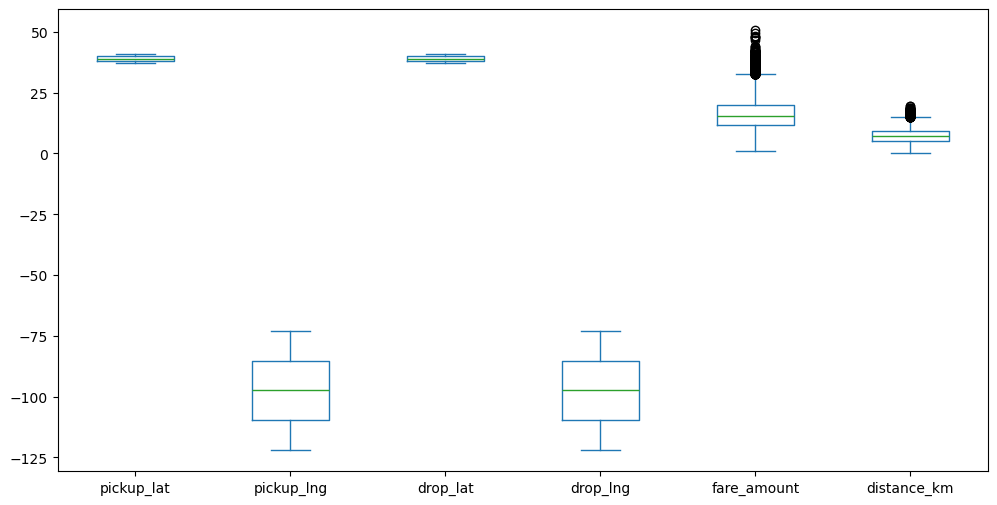

In [11]:
df[['pickup_lat', 'pickup_lng','drop_lat', 'drop_lng','fare_amount','distance_km']].plot(kind='box',figsize=(12,6))

In [12]:
cols = ['pickup_lat', 'pickup_lng', 'drop_lat', 'drop_lng', 'fare_amount', 'distance_km']

for col in cols:
    q1 = df[col].quantile(0.25)
    q3 = df[col].quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    
    outliers = df[(df[col] < lower_bound) | (df[col] > upper_bound)]
    print(f"{col} : {len(outliers)}")


pickup_lat : 0
pickup_lng : 0
drop_lat : 0
drop_lng : 0
fare_amount : 495
distance_km : 208


In [13]:
# 1. تحويل أعمدة الوقت بدون dayfirst لأن التنسيق قياسي (YYYY-MM-DD)
df['pickup_time'] = pd.to_datetime(df['pickup_time'])
df['drop_time'] = pd.to_datetime(df['drop_time'])

# 2. استخراج اليوم، الشهر، السنة، والوقت
df['day'] = df['pickup_time'].dt.day
df['month'] = df['pickup_time'].dt.month
df['year'] = df['pickup_time'].dt.year
df['hour'] = df['pickup_time'].dt.hour
df['time'] = df['pickup_time'].dt.strftime('%H:%M')

# 3. استخراج أسماء الأيام والشهور (ممتازة للرسوم البيانية في الداشبورد)
df['day_name'] = df['pickup_time'].dt.day_name()
df['month_name'] = df['pickup_time'].dt.month_name()

# 4. (إضافة مهمة للداشبورد) حساب مدة الرحلة بالدقائق
df['trip_duration_min'] = (df['drop_time'] - df['pickup_time']).dt.total_seconds() / 60
df['trip_duration_min'] = df['trip_duration_min'].round(2)

# عرض أول 5 صفوف للتأكد من النتيجة
df[['pickup_time', 'day', 'month', 'year', 'hour', 'day_name', 'trip_duration_min']].head()

,pickup_time,day,month,year,hour,day_name,trip_duration_min
0,2023-01-01 00:00:00,1,1,2023,0,Sunday,8.91
1,2023-01-01 00:01:00,1,1,2023,0,Sunday,25.29
2,2023-01-01 00:02:00,1,1,2023,0,Sunday,16.38
3,2023-01-01 00:03:00,1,1,2023,0,Sunday,19.83
4,2023-01-01 00:04:00,1,1,2023,0,Sunday,31.50


In [14]:
df['drop_time'] = pd.to_datetime(df['drop_time']).dt.round('s')

df['drop_time_only'] = df['drop_time'].dt.strftime('%H:%M:%S')


In [15]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 23 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   trip_id            50000 non-null  int64         
 1   driver_id          50000 non-null  int64         
 2   rider_id           50000 non-null  int64         
 3   city               50000 non-null  object        
 4   pickup_lat         50000 non-null  float64       
 5   pickup_lng         50000 non-null  float64       
 6   drop_lat           50000 non-null  float64       
 7   drop_lng           50000 non-null  float64       
 8   distance_km        50000 non-null  float64       
 9   fare_amount        50000 non-null  float64       
 10  status             50000 non-null  object        
 11  payment_method     50000 non-null  object        
 12  pickup_time        50000 non-null  datetime64[ns]
 13  drop_time          50000 non-null  datetime64[ns]
 14  day   

In [16]:
Total_trips=df['trip_id'].count()
print(f"Total Trips: {Total_trips}")

Total Trips: 50000


In [17]:
Total_drivers=df['driver_id'].nunique()
print(f"Total Drivers: {Total_drivers}")

Total Drivers: 8963


In [18]:
total_riders=df['rider_id'].nunique()
print(f"Total Riders: {total_riders}")

Total Riders: 38352


In [19]:
AVG_distance=df['distance_km'].mean()
print(f"Average Distance: {AVG_distance:.2f} km")

Average Distance: 7.01 km


In [20]:
Total_amount=df['fare_amount'].sum()
print(f"Total Fare Amount: {Total_amount:.2f} USD")

Total Fare Amount: 798810.27 USD


In [21]:
completion_rate = (df['status'] == 'Completed').mean() * 100
print(f"Completion Rate: {completion_rate:.2f}%")

Completion Rate: 85.08%


In [22]:
completed_count = (df['status'] == 'Completed').sum()
print(f"Completed Trips Count: {completed_count}")

Completed Trips Count: 42540


In [23]:
no_show_count = (df['status'] == 'No-Show').sum()
print(f"No-Show Trips Count: {no_show_count}")

No-Show Trips Count: 2476


In [24]:
Cancelled_count = (df['status'] == 'Cancelled').sum()
print(f"Cancelled Trips Count: {Cancelled_count}")

Cancelled Trips Count: 4984


In [25]:
df['actual_revenue'] = df.apply(lambda row: row['fare_amount'] if row['status'] == 'Completed' else 0, axis=1)
df['actual_revenue'] = np.where(df['status'] == 'Completed', df['fare_amount'], 0)
df['lost_revenue'] = np.where(df['status'] != 'Completed', df['fare_amount'], 0)

In [26]:
revenue_by_status = (
    df.groupby('status')[['actual_revenue', 'lost_revenue']]
    .sum()
    .sort_values(by='actual_revenue', ascending=False)
)
revenue_by_status

,actual_revenue,lost_revenue
status,,
Completed,679684.88,0.00
Cancelled,0.00,79606.14
No-Show,0.00,39519.25


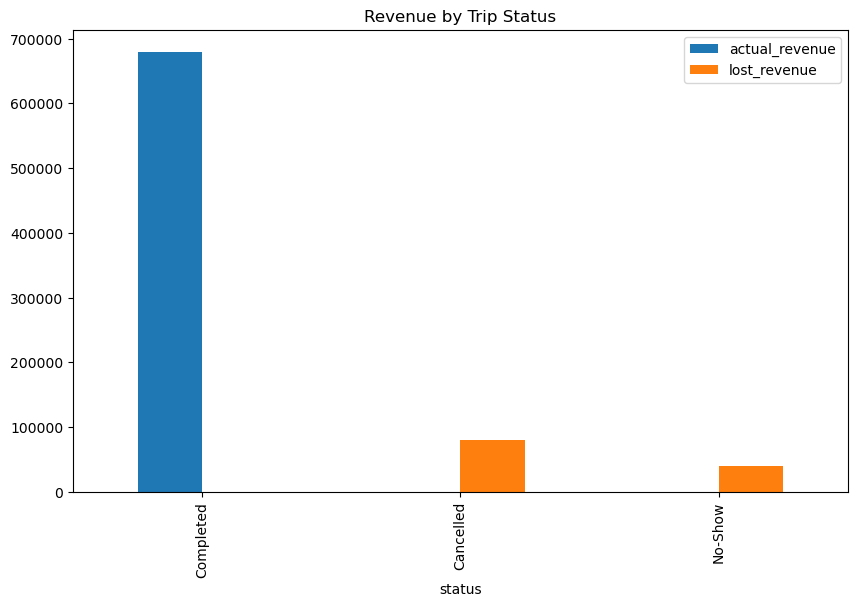

In [27]:
plot = revenue_by_status.plot(kind='bar', figsize=(10, 6), title='Revenue by Trip Status')

In [28]:
revenue_by_city = (
    df.groupby('city')['actual_revenue']
    .sum().sort_values( ascending=False)
)
revenue_by_city

city
Boston           115028.20
San Francisco    114660.65
Seattle          113343.20
New York         113175.20
Chicago          112791.09
Los Angeles      110686.54
Name: actual_revenue, dtype: float64

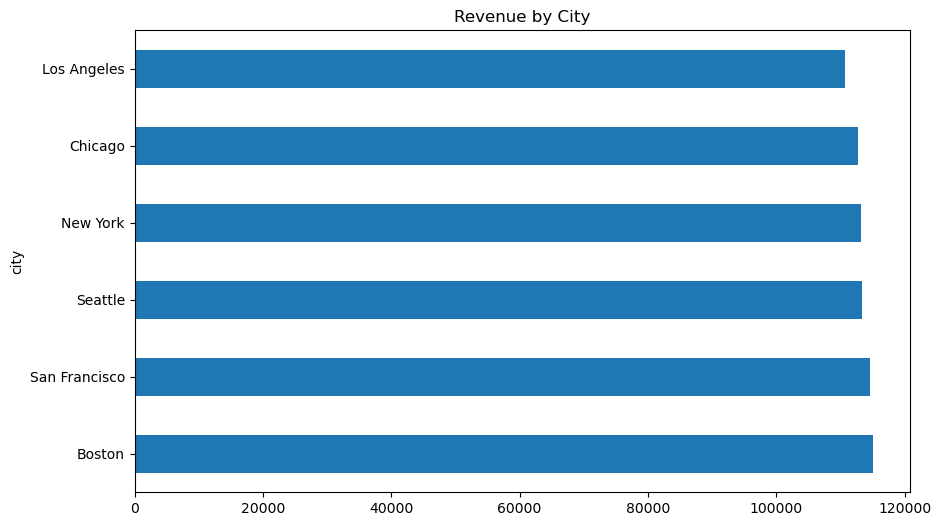

In [29]:
plt = revenue_by_city.plot(kind='barh', figsize=(10, 6),
 title='Revenue by City')

In [30]:
Total_trips_by_city = ( 
df.groupby('city')['trip_id'].count()
.sort_values(ascending=False)
)
Total_trips_by_city

city
Boston           8454
San Francisco    8401
Chicago          8345
Los Angeles      8315
New York         8247
Seattle          8238
Name: trip_id, dtype: int64

AttributeError: 'Axes' object has no attribute 'xticks'

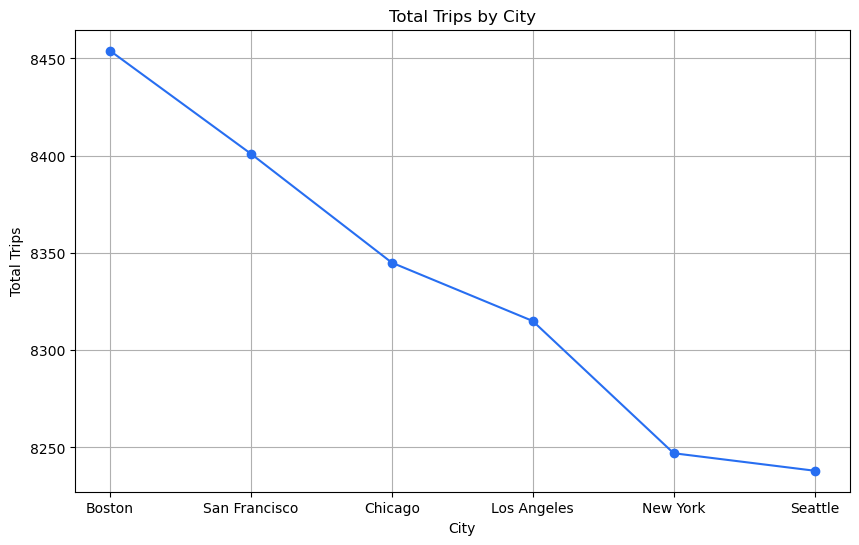

In [31]:

# نسمي المتغير ax وليس plt أبداً
ax = Total_trips_by_city.plot(
    kind='line', 
    figsize=(10, 6), 
    title='Total Trips by City',
    marker='o',
    color='#276EF1',
    grid=True
)

ax.set_xlabel('City')
ax.set_ylabel('Total Trips')
plt.xticks(rotation=45)
plt.show()

In [ ]:
revenue_by_payment = (
    df.groupby('payment_method')['actual_revenue']
    .sum()
    .sort_values(ascending=False)
    .to_frame("Actual Revenue")
)
revenue_by_payment

,Actual Revenue
payment_method,
Card,171143.20
Wallet,170020.05
UPI,169951.07
Cash,168570.56


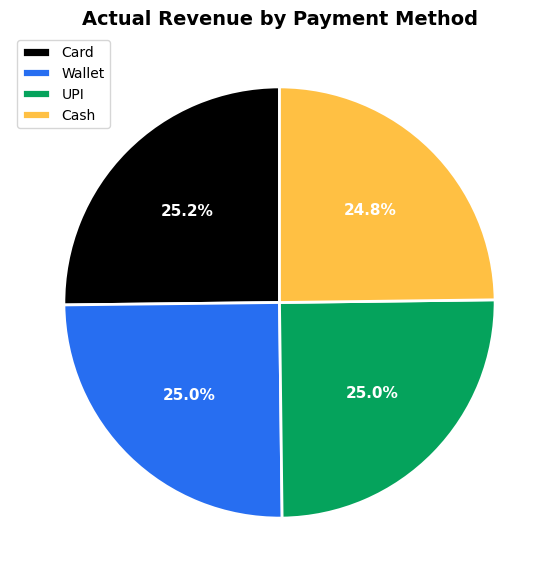

In [ ]:
ax = revenue_by_payment['Actual Revenue'].plot(
    kind='pie',
    figsize=(7, 7),
    autopct='%1.1f%%',
    startangle=90,
    colors=['#000000', '#276EF1', '#05A35C', '#FFC043'],
    textprops={'color': 'white', 'weight': 'bold', 'fontsize': 11},
    wedgeprops={'edgecolor': 'white', 'linewidth': 2}
)

ax.set_title('Actual Revenue by Payment Method', fontsize=14, fontweight='bold')
ax.set_ylabel('') 
plt.legend(revenue_by_payment.index, loc="best")
plt.show()

In [ ]:
busiest_hours = (
    df.groupby('hour')['trip_id']
    .count()
    .sort_values(ascending=False)
    .to_frame("Total Trips")
)
display(busiest_hours.head())  # يعرض أعلى 5 ساعات نشاطاً

,Total Trips
hour,
0,2100
1,2100
2,2100
3,2100
4,2100


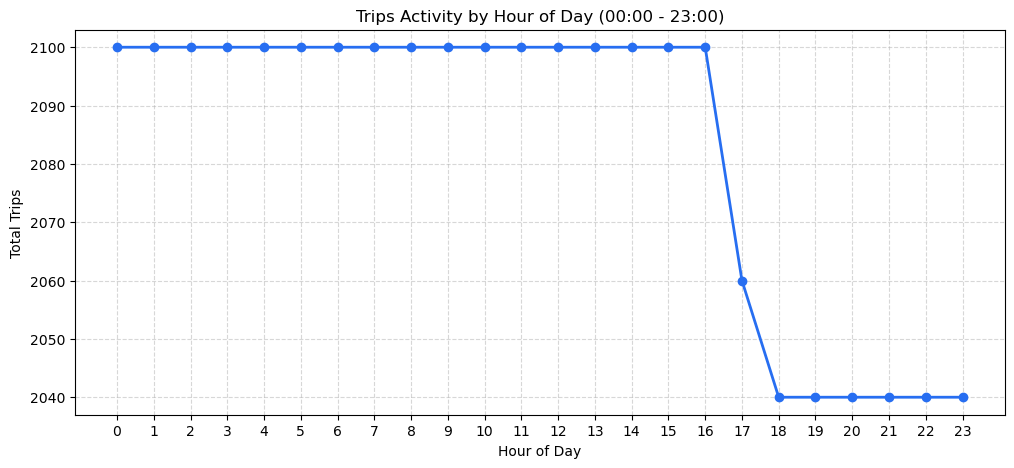

In [ ]:
hourly_trend = df.groupby('hour')['trip_id'].count()
ax = hourly_trend.plot(
    kind='line', figsize=(12, 5), marker='o', color='#276EF1', linewidth=2,
    title='Trips Activity by Hour of Day (00:00 - 23:00)'
)
ax.set_xticks(range(0, 24))
ax.set_xlabel('Hour of Day')
ax.set_ylabel('Total Trips')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [ ]:
busiest_days = (
    df.groupby('day_name')['trip_id']
    .count()
    .sort_values(ascending=False)
    .to_frame("Total Trips")
)
display(busiest_days)

,Total Trips
day_name,
Friday,7200
Monday,7200
Sunday,7200
Tuesday,7200
Thursday,7200
Wednesday,7200
Saturday,6800


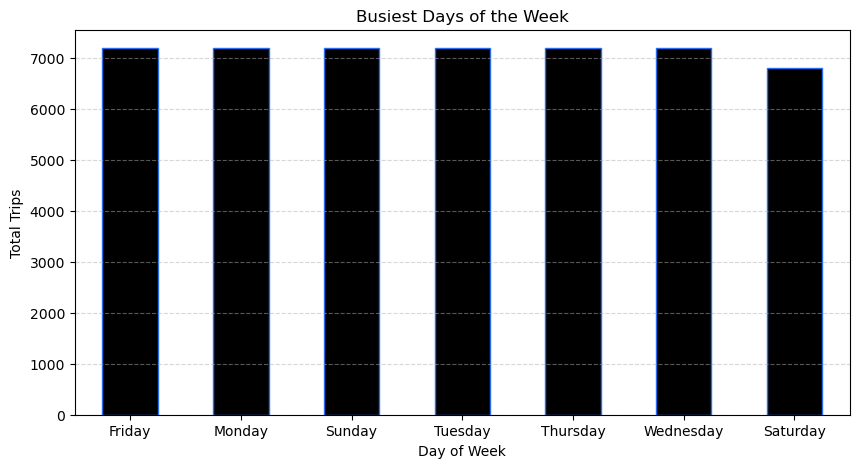

In [ ]:
ax = busiest_days.plot(
    kind='bar', figsize=(10, 5), color='#000000', edgecolor='#276EF1',
    title='Busiest Days of the Week', legend=False, rot=0
)
ax.set_xlabel('Day of Week')
ax.set_ylabel('Total Trips')
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.show()

In [ ]:
monthly_demand = (
    df.groupby('month_name')
    .agg(
        Total_Trips=('trip_id', 'count'),
        Actual_Revenue=('actual_revenue', 'sum')
    )
    .sort_values(by='Total_Trips', ascending=False)
)
display(monthly_demand)

,Total_Trips,Actual_Revenue
month_name,,
January,44640,606699.99
February,5360,72984.89


In [ ]:
def get_time_slot(hour):
    if 6 <= hour < 10:
        return 'Morning Rush (6AM-10AM)'
    elif 10 <= hour < 16:
        return 'Midday (10AM-4PM)'
    elif 16 <= hour < 20:
        return 'Evening Rush (4PM-8PM)'
    elif 20 <= hour <= 23:
        return 'Night (8PM-12AM)'
    else:
        return 'Late Night (12AM-6AM)'

df['time_slot'] = df['hour'].apply(get_time_slot)

In [ ]:
peak_slots = (
    df.groupby('time_slot')['trip_id']
    .count()
    .sort_values(ascending=False)
    .to_frame("Total Trips")
)
display(peak_slots)

,Total Trips
time_slot,
Late Night (12AM-6AM),12600
Midday (10AM-4PM),12600
Morning Rush (6AM-10AM),8400
Evening Rush (4PM-8PM),8240
Night (8PM-12AM),8160


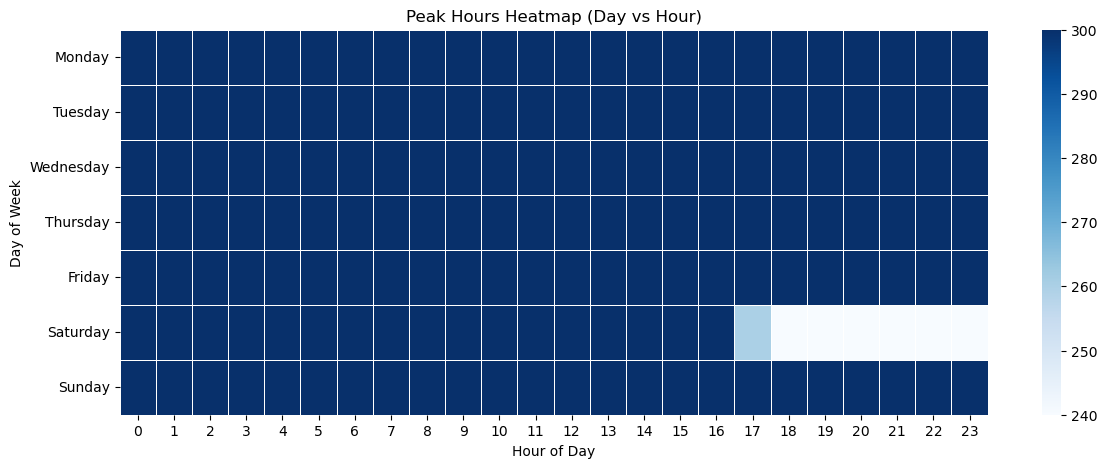

In [ ]:
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
heatmap_data = df.pivot_table(index='day_name', columns='hour', values='trip_id', aggfunc='count').reindex(days_order)

plt.figure(figsize=(14, 5))
sns.heatmap(heatmap_data, cmap='Blues', linewidths=0.5)
plt.title('Peak Hours Heatmap (Day vs Hour)')
plt.xlabel('Hour of Day')
plt.ylabel('Day of Week')
plt.show()

In [ ]:
top_drivers_total = (
    df.groupby('driver_id')['trip_id']
    .count()
    .sort_values(ascending=False)
    .to_frame("Total Trips")
)
display(top_drivers_total.head(10))

,Total Trips
driver_id,
9998,16
6599,16
3925,16
3415,15
1027,15
5014,15
6700,14
5780,14
6906,14


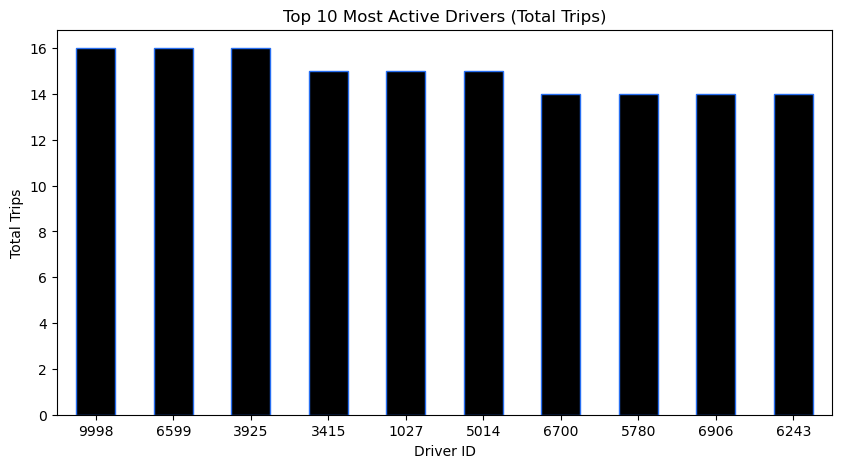

In [ ]:
ax = top_drivers_total.head(10).plot(
    kind='bar', figsize=(10, 5), color='#000000', edgecolor='#276EF1',
    title='Top 10 Most Active Drivers (Total Trips)', legend=False, rot=0
)
ax.set_xlabel('Driver ID')
ax.set_ylabel('Total Trips')
plt.show()

In [ ]:
completed_df = df[df['status'] == 'Completed']

completed_per_driver = (
    completed_df.groupby('driver_id')['trip_id']
    .count()
    .sort_values(ascending=False)
    .to_frame("Completed Trips")
)
display(completed_per_driver.head(10))

,Completed Trips
driver_id,
6599,15
8008,14
5014,14
1027,14
3415,13
3925,13
3800,13
9325,13
2308,13


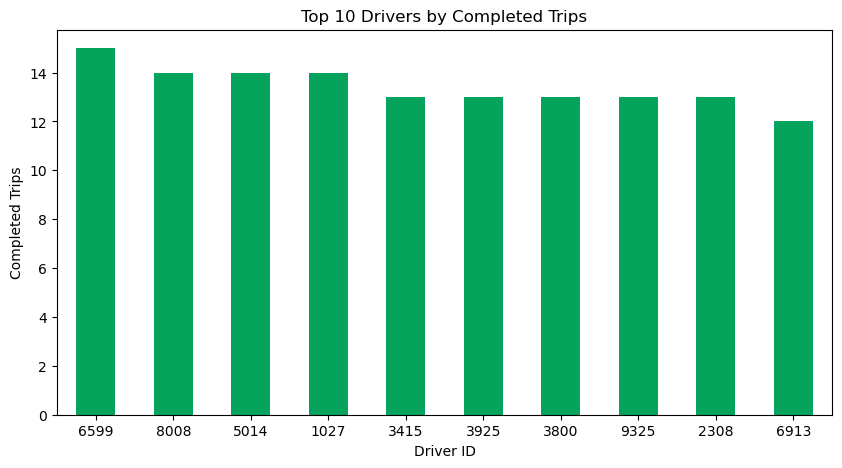

In [ ]:
ax = completed_per_driver.head(10).plot(
    kind='bar', figsize=(10, 5), color='#05A35C',
    title='Top 10 Drivers by Completed Trips', legend=False, rot=0
)
ax.set_xlabel('Driver ID')
ax.set_ylabel('Completed Trips')
plt.show()

In [ ]:
# عدد السائقين النشطين في كل ساعة من اليوم
active_drivers_by_hour = (
    df.groupby('hour')['driver_id']
    .nunique()  # يحسب عدد السائقين الفريدين بدون تكرار
    .to_frame("Active Drivers Count")
)
display(active_drivers_by_hour.head())

,Active Drivers Count
hour,
0,1852
1,1871
2,1874
3,1858
4,1875


In [ ]:


# حساب سعر الكيلومتر لكل رحلة (مع تجنب القسمة على صفر)
df['fare_per_km'] = np.where(df['distance_km'] > 0, df['fare_amount'] / df['distance_km'], np.nan)

# 1. متوسط سعر الكيلومتر (بطريقة متوسط النسب للرحلات المكتملة السليمة)
valid_completed = df[(df['status'] == 'Completed') & (df['distance_km'] > 0)]
avg_fare_per_km = valid_completed['fare_per_km'].mean()

# 2. المعدل الموزون العام (إجمالي الإيراد الفعلي ÷ إجمالي الكيلومترات المقطوعة)
weighted_fare_per_km = valid_completed['fare_amount'].sum() / valid_completed['distance_km'].sum()

print(f"Average Fare per KM (Per Trip Mean): ${avg_fare_per_km:.2f} / km")
print(f"Weighted Overall Fare per KM: ${weighted_fare_per_km:.2f} / km")

Average Fare per KM (Per Trip Mean): $2.62 / km
Weighted Overall Fare per KM: $2.28 / km


Correlation between Distance and Fare: 0.87


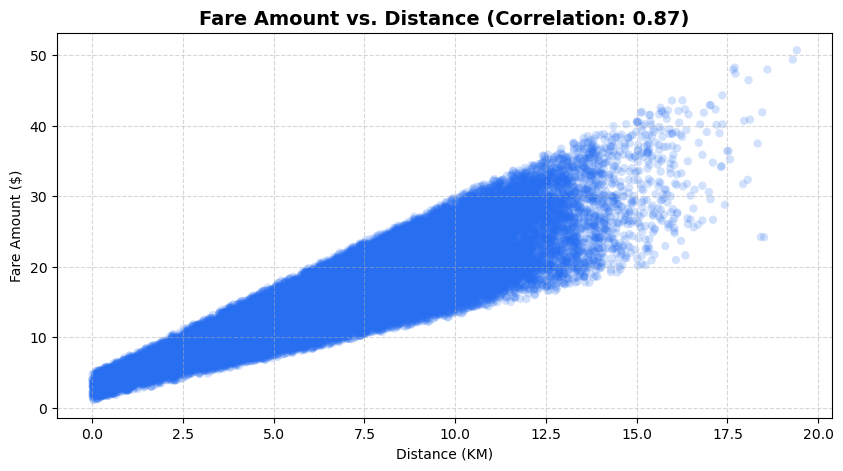

In [ ]:
# حساب معامل الارتباط بين المسافة والأجرة
correlation = df['distance_km'].corr(df['fare_amount'])
print(f"Correlation between Distance and Fare: {correlation:.2f}")

# رسم Scatter Plot لتوضيح العلاقة
plt.figure(figsize=(10, 5))
plt.scatter(
    df['distance_km'], 
    df['fare_amount'], 
    alpha=0.2, 
    color='#276EF1', 
    edgecolors='none'
)

plt.title(f'Fare Amount vs. Distance (Correlation: {correlation:.2f})', fontsize=14, fontweight='bold')
plt.xlabel('Distance (KM)')
plt.ylabel('Fare Amount ($)')
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

In [34]:
df.to_csv('final_dataset.csv', index=False)